# SVM 2 실습: 알파 학습과 소프트 마진

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/ml1/week02/3_svm_soft/lab/svm_soft.ipynb)

- **파트 1**: 슬라이드의 점 20개에서 α 를 J 로 직접 학습하기
- **파트 2**: 이상치 하나 넣고 소프트 마진

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC


## 슬라이드의 예시 데이터

원래 값에서 축마다 평균을 빼고 표준편차로 나눈다 (z-score). 슬라이드의 점은 이 값을 소수 첫째 자리로 반올림한 것.

In [ ]:
# Same example as the slides: 10 red (+1) and 10 blue (-1) points, raw values
X_raw = np.array([[5.9, 6.8], [5.3, 8.0], [6.3, 6.2], [6.1, 9.2], [5.5, 7.4], [6.6, 8.6], [5.7, 5.6], [5.5, 9.8], [6.6, 6.8], [4.8, 8.9],   # red
              [4.4, 1.1], [3.8, 1.7], [4.6, 2.3], [4.0, 3.2], [3.6, 0.5], [4.4, 3.8], [5.1, 1.7], [3.4, 3.2], [4.8, 0.8], [3.7, 4.4]])  # blue
y = np.array([1] * 10 + [-1] * 10)
X = None  # TODO: z-score each column, round to 1 decimal
print("mean", X.mean(0).round(2), " std", X.std(0).round(2))

def plot_svm(model, X, y, ax=None, title=""):
    ax = ax or plt.gca()
    gx, gy = np.meshgrid(np.linspace(-2.2, 2.2, 200), np.linspace(-2.2, 2.2, 200))
    Z = model.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contour(gx, gy, Z, levels=[-1, 0, 1], linestyles=["--", "-", "--"], colors="k")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm_r")
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=200, facecolors="none", edgecolors="gold", linewidths=2)
    ax.set_aspect("equal"); ax.set_title(title)

**예상 결과**

```
mean [0.01 0.  ]  std [0.99 1.01]
```

## 파트 1. $\alpha$ 를 $J$ 로 직접 학습

점마다 $\alpha_k \ge 0$ 하나. 시작은 $\alpha_k = 1/$(같은 색 점 수), $b = 0$ ($\mathbf{w}$ = 빨강 평균 − 파랑 평균). 한 걸음: $\alpha_k \leftarrow \max(0,\ \alpha_k + \eta(1 - y_k D(\mathbf{x}_k)))$, $b \leftarrow b + \eta\sum_k \alpha_k y_k$, 여기서 $D(\mathbf{x}) = \sum_l \alpha_l y_l (\mathbf{x}_l\cdot\mathbf{x}) + b$. 끝나면 $\mathbf{w} = \sum_k \alpha_k y_k \mathbf{x}_k$.

In [ ]:
# Learn alpha by increasing J (dual problem)
def train_dual(X, y, steps=20000, eta=0.05):
    G = X @ X.T                                            # dot products x_k . x_l
    a, b = np.where(y > 0, 1 / (y > 0).sum(), 1 / (y < 0).sum()), 0.0   # start: w = red mean - blue mean
    for t in range(steps):
        v = y * (G @ (a * y) + b)                          # y_k D(x_k)
        a = None  # TODO: push alpha by (1 - v), keep it >= 0
        b = b + eta * (a @ y)
    return a, b

a, b = train_dual(X, y)
w = None  # TODO: w = sum_k alpha_k y_k x_k
print("w", w.round(2), " b", round(b, 2))
print("support vectors", X[a > 1e-6].tolist(), " alpha", a[a > 1e-6].round(3))
m = SVC(kernel="linear", C=1e6).fit(X, y)
print("sklearn w", m.coef_[0].round(2), " b", m.intercept_.round(2))

**예상 결과**

```
w [1.05 1.05]  b 0.05
support vectors [[0.7, 0.2], [-0.6, -0.4], [0.1, -1.1]]  alpha [1.108 0.554 0.554]
sklearn w [1.05 1.05]  b [0.05]
```

## 파트 2. 소프트 마진

빨간 이상치 하나를 파란 쪽에 넣는다. sklearn 의 `C` 는 슬라이드의 $C$ 와 같다: 크면 좁은 길, 작으면 넓은 길. 마진 $M = 1/\lVert\mathbf{w}\rVert$.

In [ ]:
# Soft margin: add one red outlier inside the blue group
X_out = np.r_[X, [[-0.2, -0.6]]]; y_out = np.r_[y, [1]]
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, C in zip(axs, [100, 3, 0.3]):
    m = SVC(kernel="linear", C=C).fit(X_out, y_out)
    n_sv = None  # TODO: number of support vectors
    plot_svm(m, X_out, y_out, ax, f"C={C}: M {1 / np.linalg.norm(m.coef_[0]):.2f}, {n_sv} SVs")   # margin M = 1/||w|| (nearest value = 1)
plt.show()

**예상 결과**

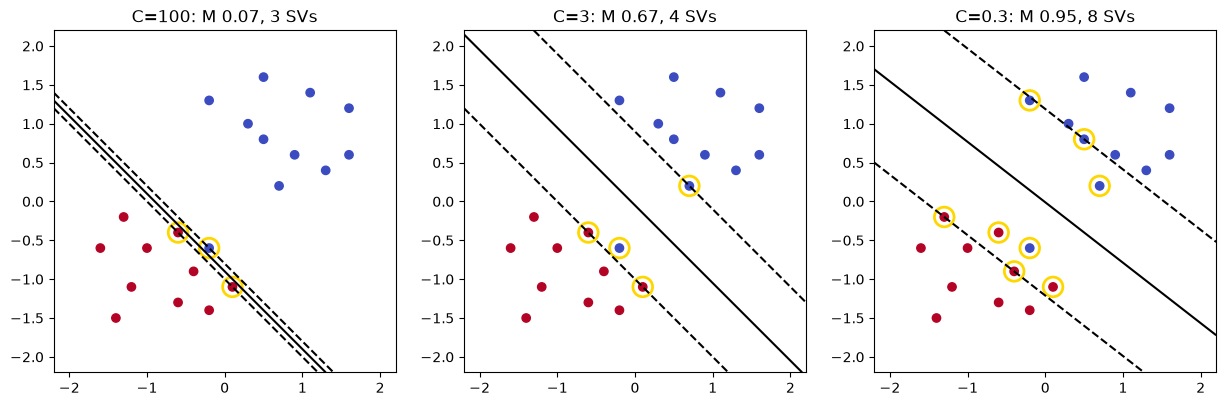

**확인 질문**
1. 파트 1 에서 α 가 0 이 아닌 점은 몇 개인가? 그 점들은 그림의 어디에 있나?
2. 파트 1 에서 서포트 벡터가 아닌 점 하나를 지우고 다시 학습하면 w 는 바뀌나?
3. 파트 2 에서 C 를 줄일수록 서포트 벡터 수는 어떻게 되나? 왜 그럴까?